**Cell 1 — Installation and IMF Report Loading**

In [ ]:

# Install the libraries used throughout Task 1.
%pip install -q pymupdf tiktoken huggingface_hub requests

from pathlib import Path
from huggingface_hub import hf_hub_download
from IPython.display import display, Markdown
import fitz, tiktoken, requests, json, re, hashlib
import subprocess, shutil, time, os

ROOT = Path("/content/mali_imf")
ROOT.mkdir(parents=True, exist_ok=True)

PDF = ROOT / "Mali.pdf"
URL = "https://www.imf.org/-/media/files/publications/cr/2023/english/1mliea2023001.pdf"

def save_json(name, data):
    with (ROOT / name).open("w", encoding="utf-8") as file:
        json.dump(data, file, indent=2, ensure_ascii=False)

# Prefer the uploaded PDF; otherwise retrieve the official IMF copy.
if not PDF.exists():
    uploaded = Path("/content/Mali.pdf")
    if uploaded.exists():
        shutil.copy2(uploaded, PDF)
    else:
        response = requests.get(URL, timeout=120)
        response.raise_for_status()
        PDF.write_bytes(response.content)

with fitz.open(PDF) as document:
    assert len(document) == 100, "Unexpected report length."
    assert "23/209" in document[0].get_text(), "Incorrect IMF report."
    raw_pages = [page.get_text("text", sort=True) for page in document]

def clean_text(text):
    # Repair broken words while keeping financial table rows intact.
    text = re.sub(r"(?m)^\s*(MALI|INTERNATIONAL MONETARY FUND)\s*$", "", text)
    text = re.sub(r"(?<=\w)-\n(?=\w)", "", text)
    text = re.sub(r"(?<=[a-z,;])\n(?=[a-z])", " ", text)
    return re.sub(r"\n{3,}", "\n\n", text).strip()

pages = [clean_text(text) for text in raw_pages]
full_text = "\n\n".join(pages)
source_hash = hashlib.sha256(PDF.read_bytes()).hexdigest()

(ROOT / "cleaned_report.txt").write_text(full_text, encoding="utf-8")

print(f"IMF report: Mali (2023) | {len(pages)} pages")
print(f"Extracted characters: {len(full_text):,}")


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


IMF report: Mali (2023) | 100 pages
Extracted characters: 513,284


**Cell 2 — Token-Aware Chunking and Section Identification**

In [ ]:

# Keep each chunk linked to its original PDF page.
encoder = tiktoken.get_encoding("cl100k_base")
WINDOW, OVERLAP = 400, 50
chunks = []

for page_no, text in enumerate(pages, 1):
    tokens = encoder.encode(text)
    start = 0

    while start < len(tokens):
        end = min(start + WINDOW, len(tokens))

        chunks.append({
            "page": page_no,
            "text": encoder.decode(tokens[start:end]),
            "token_count": end - start
        })

        if end == len(tokens):
            break
        start = end - OVERLAP

save_json("task1_chunks.json", chunks)

# PDF page references include the report's main sections and annexes.
sections = {
    "Press Release": (1, 4),
    "Key Issues and Contents": (5, 7),
    "Context": (8, 8),
    "Economic Growth and Developments": (8, 10),
    "Financing Conditions": (11, 13),
    "Outlook and Risks": (14, 16),
    "Fiscal Policy Discussions": (17, 18),
    "Protecting Vulnerable Groups": (19, 19),
    "Unlocking Growth Potential": (19, 20),
    "WAEMU Policy Recommendations": (21, 21),
    "Other Issues": (21, 22),
    "Staff Appraisal": (22, 23),
    "Economic Figures and Tables": (24, 36),
    "Country Engagement Strategy": (37, 43),
    "Political Developments": (44, 45),
    "Economic Shocks and Sanctions": (46, 49),
    "External Sector Assessment": (50, 53),
    "IMF Engagement": (54, 58),
    "Risk Assessment Matrix": (59, 60),
    "Alternative Economic Scenario": (61, 62),
    "Capacity Development Strategy": (63, 64),
    "Informational Annex": (65, 74),
    "Debt Sustainability Analysis": (75, 95),
    "Executive Director Statement": (96, 100)
}

def section_blocks(first, last, size=2800):
    # Split the whole section into manageable model inputs.
    text = "\n".join(
        f"[PDF page {p}]\n{pages[p - 1]}"
        for p in range(first, last + 1)
    )
    tokens = encoder.encode(text)
    return [
        encoder.decode(tokens[i:i + size])
        for i in range(0, len(tokens), size)
    ]

assert len(chunks) > 0
assert all(c["token_count"] <= WINDOW for c in chunks)
assert set(range(1, 101)) == {
    p for first, last in sections.values()
    for p in range(first, last + 1)
}

print(f"Token-aware chunks: {len(chunks)}")
print(f"Major sections: {len(sections)}")
print("Chunk size: 400 tokens | Overlap: 50 tokens")


Token-aware chunks: 254
Major sections: 24
Chunk size: 400 tokens | Overlap: 50 tokens


**Cell 3 — Qwen3.5-2B Installation and LLM Functions**

In [ ]:

# Cell 3 — Qwen3.5-2B Model Setup

from pathlib import Path
from huggingface_hub import hf_hub_download
import requests, subprocess, shutil, hashlib, json, time, os

ROOT = Path("/content/mali_imf")
ROOT.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "Qwen3.5-2B-Q4_K_M.gguf"
API = "http://127.0.0.1:8090"

# Download once and reuse the model on subsequent runs.
MODEL_PATH = Path(hf_hub_download(
    repo_id="unsloth/Qwen3.5-2B-GGUF",
    filename=MODEL_NAME,
    local_dir=str(ROOT / "model")
))

# Reuse the existing llama.cpp installation where possible.
REPO = ROOT / "llama.cpp"
GPU = shutil.which("nvidia-smi") is not None

if not (REPO / "CMakeLists.txt").exists():
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/ggml-org/llama.cpp.git",
        str(REPO)
    ], check=True)

# A separate CUDA build avoids accidentally reusing a CPU build.
NVCC = shutil.which("nvcc") or "/usr/local/cuda/bin/nvcc"
CUDA = GPU and Path(NVCC).exists()
BUILD = REPO / ("build_cuda" if CUDA else "build_cpu")
SERVER = BUILD / "bin/llama-server"

if not SERVER.exists():
    subprocess.run([
        "cmake", "-S", str(REPO), "-B", str(BUILD),
        f"-DGGML_CUDA={'ON' if CUDA else 'OFF'}",
        "-DCMAKE_BUILD_TYPE=Release"
    ], check=True)

    subprocess.run([
        "cmake", "--build", str(BUILD),
        "--target", "llama-server", "-j", "4"
    ], check=True)

def ready():
    try:
        return requests.get(f"{API}/health", timeout=3).status_code == 200
    except requests.RequestException:
        return False

# Start the server only when it is not already running.
if not ready():
    command = [
        str(SERVER),
        "-m", str(MODEL_PATH),
        "-c", "8192",
        "-ngl", "99" if CUDA else "0",
        "--host", "127.0.0.1",
        "--port", "8090"
    ]

    with (ROOT / "server.log").open("w") as log:
        process = subprocess.Popen(
            command,
            stdout=log,
            stderr=subprocess.STDOUT
        )

    for _ in range(90):
        if ready():
            break
        if process.poll() is not None:
            break
        time.sleep(2)

if not ready():
    logs = (ROOT / "server.log").read_text(errors="replace")
    raise RuntimeError(
        "Qwen server startup failed:\n" + logs[-2500:]
    )

print("Qwen3.5-2B model is running successfully.")
print("GPU acceleration:", "Enabled" if CUDA else "Not enabled")

# Shared function for Task 1 summarisation and evaluation.
source_hash = hashlib.sha256(
    (ROOT / "Mali.pdf").read_bytes()
).hexdigest()

def generate(prompt, system, limit=180, json_mode=False):
    key = hashlib.sha256(
        (source_hash + MODEL_NAME + system + prompt +
         str(limit) + str(json_mode)).encode()
    ).hexdigest()

    cache = ROOT / f"cache_{key}.json"

    if cache.exists():
        return json.loads(cache.read_text())["answer"]

    payload = {
        "model": "local",
        "messages": [
            {"role": "system", "content": system},
            {"role": "user", "content": prompt}
        ],
        "temperature": 0,
        "max_tokens": limit
    }

    if json_mode:
        payload["response_format"] = {"type": "json_object"}

    response = requests.post(
        f"{API}/v1/chat/completions",
        json=payload,
        timeout=480
    )
    response.raise_for_status()

    answer = response.json()["choices"][0]["message"]["content"].strip()

    if not answer:
        raise ValueError("The model returned an empty response.")

    cache.write_text(
        json.dumps({"answer": answer}),
        encoding="utf-8"
    )

    return answer


Qwen3.5-2B-Q4_K_M.gguf: reconstructing file:   0%|          |  0.00B / 1.28GB            

Qwen3.5-2B-Q4_K_M.gguf: downloading bytes:           |  0.00B            

Qwen3.5-2B model is running successfully.
GPU acceleration: Enabled


**Cell 4 — Executive Summary and Section Summarisation**

In [ ]:

# CELL 4 — EXECUTIVE AND SECTION SUMMARISATION

import json
import re
import time
from IPython.display import display, Markdown

SYSTEM = (
    "You are an IMF financial analyst. Summarise only the supplied "
    "evidence. Preserve financial figures, dates, forecasts and risks. "
    "Write clearly, accurately and without unnecessary explanation."
)

# Continue from previously saved results.
summary_file = ROOT / "task1_section_summaries.json"
notes_file = ROOT / "task1_source_notes.json"

section_summaries = (
    json.loads(summary_file.read_text(encoding="utf-8"))
    if summary_file.exists() else {}
)

source_notes = (
    json.loads(notes_file.read_text(encoding="utf-8"))
    if notes_file.exists() else {}
)

review_file = ROOT / "task1_review_needed.json"
review_needed = (
    json.loads(review_file.read_text(encoding="utf-8"))
    if review_file.exists() else []
)


def enforce_word_limit(text, title):
    """Keep summaries below 100 words without stopping execution."""

    if 0 < len(text.split()) < 100:
        return text

    # Give Qwen two opportunities to produce a shorter summary.
    for target in (75, 65):
        text = generate(
            f"Rewrite this IMF summary as one paragraph of no more "
            f"than {target} words. Keep the most important numerical "
            f"facts, findings and risks. Output the paragraph only.\n\n"
            + text,
            SYSTEM,
            limit=150
        )

        if 0 < len(text.split()) < 100:
            return text

    # Safety fallback: avoid another crash if the word limit is ignored.
    words = text.split()
    shortened = " ".join(words[:94])

    # Prefer ending at a complete sentence.
    sentences = re.split(r"(?<=[.!?])\s+", shortened)
    complete = " ".join(sentences[:-1])

    if len(complete.split()) >= 55:
        shortened = complete
    else:
        shortened = shortened.rstrip(",;: ") + "..."

    if title not in review_needed:
        review_needed.append(title)
        save_json("task1_review_needed.json", review_needed)

    return shortened


print(f"Previously saved: {len(section_summaries)}/{len(sections)}\n")

# Summarise all sections of the IMF report.
for number, (title, (first, last)) in enumerate(sections.items(), 1):

    if title in section_summaries:
        print(f"{number:02d}. Reused: {title}", flush=True)
        continue

    started = time.perf_counter()
    blocks = section_blocks(first, last, size=4800)

    # Summarise long source passages before combining their findings.
    if len(blocks) == 1:
        evidence = blocks[0]
        notes = []
    else:
        notes = source_notes.get(title, [])

        for block in blocks[len(notes):]:
            note = generate(
                "Identify the key economic findings, numerical facts, "
                "policy recommendations and financial risks. "
                "Write approximately 60 words. "
                "Do not invent information.\n\n" + block,
                SYSTEM,
                limit=140
            )

            notes.append(note)
            source_notes[title] = notes
            save_json("task1_source_notes.json", source_notes)

        evidence = "\n".join(notes)

    # Generate the section summary.
    summary = generate(
        f"Summarise '{title}' in one clear paragraph of 70–80 words. "
        "Include the main findings, important figures and risks. "
        "Distinguish actual observations from IMF forecasts. "
        "Use only this evidence:\n\n" + evidence,
        SYSTEM,
        limit=160
    )

    summary = enforce_word_limit(summary, title)

    if not summary:
        raise RuntimeError(f"No summary generated for {title}")

    section_summaries[title] = summary
    source_notes[title] = notes

    # Save immediately so interrupted runs can resume.
    save_json("task1_section_summaries.json", section_summaries)
    save_json("task1_source_notes.json", source_notes)

    elapsed = time.perf_counter() - started

    print(
        f"{number:02d}. Completed: {title} | "
        f"{len(summary.split())} words | {elapsed:.1f}s",
        flush=True
    )


# Prepare the executive summary using all section findings.
executive = generate(
    "Write exactly six executive bullet points about Mali's "
    "2023 IMF Article IV report. Cover GDP growth, inflation, "
    "banking stability, sovereign debt, systemic financial risks "
    "and policy recommendations. Distinguish 2022 observations "
    "from 2023 forecasts. Begin each bullet with '- '.\n\n"
    + json.dumps(section_summaries, ensure_ascii=False),
    SYSTEM,
    limit=450
)

def bullet_count(text):
    return sum(
        line.strip().startswith("- ")
        for line in text.splitlines()
    )

if bullet_count(executive) != 6:
    executive = generate(
        "Rewrite the following as exactly six bullet points, "
        "each beginning with '- '. Preserve the factual content.\n\n"
        + executive,
        SYSTEM,
        limit=450
    )

# Store the full summarisation output.
save_json("task1_summaries.json", {
    "country": "Mali",
    "report": "IMF Country Report No. 23/209",
    "model": MODEL_NAME,
    "executive_summary": executive,
    "section_summaries": section_summaries,
    "sections_requiring_review": review_needed
})

display(Markdown("### Executive Summary\n\n" + executive))

print("\nTASK 1 — SUMMARISATION RESULTS")
print(f"Sections completed: {len(section_summaries)}/{len(sections)}")
print("All saved section summaries:",
      "Below 100 words" if all(
          0 < len(s.split()) < 100
          for s in section_summaries.values()
      ) else "Review required")
print("Sections requiring manual review:", len(review_needed))
print("Results saved:", ROOT / "task1_summaries.json")


Previously saved: 3/24

01. Reused: Press Release
02. Reused: Key Issues and Contents
03. Reused: Context
04. Completed: Economic Growth and Developments | 97 words | 0.4s
05. Completed: Financing Conditions | 93 words | 0.8s
06. Completed: Outlook and Risks | 88 words | 0.4s
07. Completed: Fiscal Policy Discussions | 89 words | 0.3s
08. Completed: Protecting Vulnerable Groups | 88 words | 0.3s
09. Completed: Unlocking Growth Potential | 82 words | 0.3s
10. Completed: WAEMU Policy Recommendations | 89 words | 0.7s
11. Completed: Other Issues | 77 words | 0.7s
12. Completed: Staff Appraisal | 84 words | 0.3s
13. Completed: Economic Figures and Tables | 94 words | 2.3s
14. Completed: Country Engagement Strategy | 76 words | 0.8s
15. Completed: Political Developments | 83 words | 1.0s
16. Completed: Economic Shocks and Sanctions | 94 words | 0.8s
17. Completed: External Sector Assessment | 92 words | 0.8s
18. Completed: IMF Engagement | 94 words | 0.5s
19. Completed: Risk Assessment Matri

### Executive Summary

- **GDP Growth:** Projected to rebound from 3.7% in 2022 to 5.0% in 2023, driven by agriculture and gold exports, though risks are tilted downward due to security deterioration and election delays.
- **Inflation:** Fell from 10% in 2022 to 5% in 2023 and is forecast to decline further to 2% in 2024, with a target of 5% by 2023 and 3% by 2024.
- **Banking Stability:** BCEAO raised the policy rate to 3% in February 2023, widening the Real Interest Rate Gap to -2% and financing conditions worsening due to rising global interest rates.
- **Sovereign Debt:** Public debt is projected to rise from 52.5% in 2022 to 55.2% in 2023, with a risk of distress as debt-to-GDP is forecast to reach 56% by 2028.
- **Systemic Risks:** Severe risks include deteriorating security, election delays, volatile commodities, and tightening global financial conditions; a financing crisis is expected if external budget support remains absent since 2020.
- **Recommendations:** Authorities are urged to accelerate fiscal consolidation to meet the WAEMU 3% deficit ceiling, strengthen domestic revenue mobilization, and prioritize structural reforms in governance, health, and education to unlock growth potential.


TASK 1 — SUMMARISATION RESULTS
Sections completed: 24/24
All saved section summaries: Below 100 words
Sections requiring manual review: 0
Results saved: /content/mali_imf/task1_summaries.json


**Cell 5 — LLM-as-a-Judge Evaluation and Task 1 Results**

In [ ]:

# CELL 5 — LLM EVALUATION AND TASK 1 RESULTS

import json
import re
import statistics
from pathlib import Path

# Load the summaries produced in Cell 4.
summary_file = ROOT / "task1_summaries.json"

if not summary_file.exists():
    raise FileNotFoundError("Complete Cell 4 before running Cell 5.")

data = json.loads(summary_file.read_text(encoding="utf-8"))
section_summaries = data["section_summaries"]
executive = data["executive_summary"]

assert len(section_summaries) == len(sections), "Some sections are missing."
assert all(0 < len(s.split()) < 100 for s in section_summaries.values())

JUDGE_SYSTEM = (
    "You are a strict IMF report evaluator. Assess summaries using "
    "only the supplied original report passages. Identify factual "
    "errors, missing findings and confusion between actual figures "
    "and forecasts. Give fair scores and return valid JSON only."
)

METRICS = ("consistency", "completeness", "factual_alignment")


def source_excerpt(page_no, summary, limit=450):
    """Select a relevant original passage from a PDF page."""
    tokens = encoder.encode(pages[page_no - 1])

    if len(tokens) <= limit:
        return f"[PDF page {page_no}]\n{pages[page_no - 1]}"

    keywords = set(re.findall(r"[a-z]{4,}", summary.lower()))
    positions = range(0, len(tokens), limit // 2)

    candidates = [
        encoder.decode(tokens[i:i + limit])
        for i in positions
    ]

    best = max(
        candidates,
        key=lambda text: len(
            keywords & set(re.findall(r"[a-z]{4,}", text.lower()))
        )
    )

    return f"[PDF page {page_no}]\n{best}"


def section_evidence(title, summary):
    """Select evidence across the section, not from one page alone."""
    first, last = sections[title]
    page_numbers = list(range(first, last + 1))

    keywords = set(re.findall(r"[a-z]{4,}", summary.lower()))

    ranked = sorted(
        page_numbers,
        key=lambda p: len(
            keywords & set(
                re.findall(r"[a-z]{4,}", pages[p - 1].lower())
            )
        ),
        reverse=True
    )

    selected = sorted(set([first, last] + ranked[:3]))

    evidence = "\n\n".join(
        source_excerpt(p, summary)
        for p in selected
    )

    return evidence, selected


def judge(title, summary, evidence):
    """Score the summary against independent source excerpts."""
    prompt = (
        f"SECTION: {title}\n\n"
        f"GENERATED SUMMARY:\n{summary}\n\n"
        f"ORIGINAL IMF EVIDENCE:\n{evidence}\n\n"
        "Evaluate the summary on three criteria, each scored 0–5:\n"
        "1. consistency: logical coherence and no contradictions.\n"
        "2. completeness: coverage of important findings and risks.\n"
        "3. factual_alignment: accuracy of numbers, dates and claims.\n"
        "Judge only what the supplied evidence supports. "
        "Mention limitations when evidence is incomplete.\n"
        "Return JSON with exactly these keys:\n"
        '{"consistency": 0, "completeness": 0, '
        '"factual_alignment": 0, "notes": "brief explanation"}'
    )

    for attempt in range(3):
        answer = generate(
            prompt + (
                "\nReturn a complete JSON object only."
                if attempt else ""
            ),
            JUDGE_SYSTEM,
            limit=320 + attempt * 100
        )

        try:
            match = re.search(r"\{.*\}", answer, re.S)
            if not match:
                raise ValueError("No JSON found.")

            result = json.loads(match.group())

            for metric in METRICS:
                score = result[metric]
                if type(score) not in (int, float):
                    raise ValueError(f"Invalid score type: {metric}")
                if not 0 <= score <= 5:
                    raise ValueError(f"Invalid score: {metric}")

            if not isinstance(result.get("notes"), str):
                raise ValueError("Evaluation notes are missing.")

            return result

        except (ValueError, KeyError, TypeError, json.JSONDecodeError):
            prompt += "\nUse numeric scores between 0 and 5."

    raise ValueError(f"Evaluation failed for: {title}")


# Resume from previously saved evaluations if necessary.
progress_file = ROOT / "task1_section_evaluations.json"

evaluations = (
    json.loads(progress_file.read_text(encoding="utf-8"))
    if progress_file.exists() else {}
)

# Evaluate every section against the original report.
for number, (title, summary) in enumerate(section_summaries.items(), 1):

    if title in evaluations:
        print(f"{number:02d}. Reused: {title}", flush=True)
        continue

    evidence, evidence_pages = section_evidence(title, summary)
    result = judge(title, summary, evidence)

    result["evidence_pages"] = evidence_pages
    evaluations[title] = result

    # Save each evaluation to prevent lost progress.
    save_json("task1_section_evaluations.json", evaluations)

    print(
        f"{number:02d}. Evaluated: {title} | "
        f"Factual alignment: {result['factual_alignment']}/5",
        flush=True
    )


# Evaluate the executive summary using key original IMF pages.
executive_pages = [2, 4, 5, 13, 14, 22, 36, 61, 75]

executive_evidence = "\n\n".join(
    source_excerpt(p, executive, limit=400)
    for p in executive_pages
)

executive_result = judge(
    "Executive Summary",
    executive,
    executive_evidence
)

executive_result["evidence_pages"] = executive_pages


# Calculate average section scores.
average_scores = {
    metric: round(
        statistics.mean(
            result[metric] for result in evaluations.values()
        ),
        2
    )
    for metric in METRICS
}

# Record methodology and limitations transparently.
results = {
    "country": "Mali",
    "report": "IMF Country Report No. 23/209",
    "model": MODEL_NAME,
    "evaluation_method": "Same-model LLM-as-a-Judge prompt",
    "executive_evaluation": executive_result,
    "section_evaluations": evaluations,
    "average_scores": average_scores,
    "limitations": (
        "The evaluator uses Qwen3.5-2B with separate instructions. "
        "Original report passages are sampled across each section. "
        "The scores do not replace human verification of the full PDF."
    )
}

save_json("task1_evaluation.json", results)


# Display the results clearly.
print("\nTASK 1 — EVALUATION RESULTS")
print("-" * 38)

for metric, score in average_scores.items():
    print(f"{metric.replace('_', ' ').title():25s}: {score}/5")

print("\nExecutive Summary Evaluation")
for metric in METRICS:
    print(f"{metric.replace('_', ' ').title():25s}: "
          f"{executive_result[metric]}/5")

print("\nTASK 1 — OUTPUTS")
print(f"Sections evaluated: {len(evaluations)}/{len(sections)}")
print("Summaries:", ROOT / "task1_summaries.json")
print("Evaluation:", ROOT / "task1_evaluation.json")
print("Source chunks:", ROOT / "task1_chunks.json")


01. Evaluated: Press Release | Factual alignment: 3/5
02. Evaluated: Key Issues and Contents | Factual alignment: 4/5
03. Evaluated: Context | Factual alignment: 4/5
04. Evaluated: Economic Growth and Developments | Factual alignment: 3/5
05. Evaluated: Financing Conditions | Factual alignment: 4/5
06. Evaluated: Outlook and Risks | Factual alignment: 3/5
07. Evaluated: Fiscal Policy Discussions | Factual alignment: 3/5
08. Evaluated: Protecting Vulnerable Groups | Factual alignment: 4/5
09. Evaluated: Unlocking Growth Potential | Factual alignment: 3/5
10. Evaluated: WAEMU Policy Recommendations | Factual alignment: 3/5
11. Evaluated: Other Issues | Factual alignment: 3/5
12. Evaluated: Staff Appraisal | Factual alignment: 3/5
13. Evaluated: Economic Figures and Tables | Factual alignment: 2/5
14. Evaluated: Country Engagement Strategy | Factual alignment: 3/5
15. Evaluated: Political Developments | Factual alignment: 3/5
16. Evaluated: Economic Shocks and Sanctions | Factual alignmen

**Cell 6 — Financial Theme Classification and Distribution**

In [ ]:

# CELL 6 — FINANCIAL THEME DISTRIBUTION

import re
import json

# Use the seven categories specified in the assignment.
THEMES = {
    "Inflation & Prices":
        r"\binflation\b|consumer prices?|food prices?|fuel prices?|cost.of.living",
    "Interest Rates & Credit":
        r"interest rates?|policy rate|monetary policy|credit growth|refinancing|borrowing costs?",
    "Housing & Real Estate":
        r"\bhousing\b|real estate|mortgages?|property taxation|construction",
    "Banking Capital & Liquidity":
        r"banking|commercial banks?|capital ratio|tier.?1|nonperforming|NPLs?|bank liquidity|deposits?",
    "Sovereign Debt":
        r"public debt|sovereign debt|debt service|fiscal deficit|government bonds?|treasury bills?|debt distress",
    "Labor Market Dynamics":
        r"unemployment|employment|labor market|labour market|wages?|salaries|job creation|workforce",
    "Systemic Financial Risk":
        r"financial crisis|financing crisis|financial stability|systemic risk|solvency|fragility|sanctions|security risks?"
}

assert len(THEMES) == 7 and len(chunks) > 0

theme_data = {}

for theme, keywords in THEMES.items():
    pattern = re.compile(keywords, re.I)

    # Measure coverage across the complete report.
    matches = [
        (chunk, len(pattern.findall(chunk["text"])))
        for chunk in chunks
        if pattern.search(chunk["text"])
    ]

    # Select the strongest evidence from different PDF pages.
    matches.sort(key=lambda item: item[1], reverse=True)
    examples, seen_pages = [], set()

    for chunk, score in matches:
        if chunk["page"] in seen_pages:
            continue

        examples.append({
            "page": chunk["page"],
            "text": chunk["text"][:900]
        })
        seen_pages.add(chunk["page"])

        if len(examples) == 3:
            break

    theme_data[theme] = {
        "chunk_count": len(matches),
        "coverage_pct": round(100 * len(matches) / len(chunks), 2),
        "evidence": examples
    }

save_json("task2_themes.json", theme_data)

print("TASK 2 — FINANCIAL THEME DISTRIBUTION\n")
print(f"{'Theme':32s} {'Chunks':>8s} {'Coverage':>10s}")
print("-" * 54)

for theme, info in sorted(
    theme_data.items(),
    key=lambda item: item[1]["chunk_count"],
    reverse=True
):
    print(
        f"{theme:32s} "
        f"{info['chunk_count']:8d} "
        f"{info['coverage_pct']:9.1f}%"
    )

print(f"\nTotal document chunks: {len(chunks)}")
print("Results saved: task2_themes.json")


TASK 2 — FINANCIAL THEME DISTRIBUTION

Theme                              Chunks   Coverage
------------------------------------------------------
Sovereign Debt                         73      28.7%
Systemic Financial Risk                73      28.7%
Inflation & Prices                     34      13.4%
Labor Market Dynamics                  33      13.0%
Banking Capital & Liquidity            30      11.8%
Interest Rates & Credit                22       8.7%
Housing & Real Estate                   5       2.0%

Total document chunks: 254
Results saved: task2_themes.json


**Cell 7 — Theme Interpretation, Economic Strengths and Vulnerabilities**

In [12]:

# CELL 7 — FINANCIAL STABILITY INTERPRETATION

import json
import re

ANALYST_SYSTEM = (
    "You are a financial stability analyst studying Mali's 2023 "
    "IMF Article IV report. Use only supplied evidence. "
    "Preserve dates and figures. Avoid unsupported conclusions."
)

# Continue from previous analysis if it was interrupted.
theme_file = ROOT / "task2_theme_summaries.json"
theme_summaries = (
    json.loads(theme_file.read_text(encoding="utf-8"))
    if theme_file.exists() else {}
)

for theme, details in theme_data.items():
    if theme in theme_summaries:
        print(f"Reused: {theme}")
        continue

    passages = "\n\n".join(
        f"[PDF page {item['page']}] {item['text']}"
        for item in details["evidence"]
    )

    if not passages:
        summary = "No direct evidence identified in the indexed text."
    else:
        summary = generate(
            f"Explain the IMF report's findings about '{theme}' "
            "in approximately 60 words. Identify the principal "
            "financial implications. If coverage is limited, say so. "
            "Do not invent statistics.\n\n" + passages,
            ANALYST_SYSTEM,
            limit=160
        )

    theme_summaries[theme] = {
        "summary": summary,
        "source_pages": [
            item["page"] for item in details["evidence"]
        ]
    }

    save_json("task2_theme_summaries.json", theme_summaries)
    print(f"Completed: {theme}", flush=True)

# Use substantive passages from the report's economic and risk sections.
key_pages = [5, 8, 11, 12, 13, 14, 15, 17, 19, 22, 61, 75]

evidence = "\n\n".join(
    f"[PDF page {p}]\n{pages[p - 1][:1150]}"
    for p in key_pages
)

prompt = (
    "Identify exactly SIX economic or financial strengths and "
    "SIX vulnerabilities of Mali, as discussed in this IMF report. "
    "Be specific, concise and evidence-based. "
    "Return ONLY valid JSON with this structure:\n"
    '{"strengths": ["...", "..."], '
    '"vulnerabilities": ["...", "..."]}\n\n'
    "SOURCE EVIDENCE:\n" + evidence
)

def parse_findings(response):
    match = re.search(r"\{.*\}", response, re.S)
    if not match:
        raise ValueError("The model did not return JSON.")

    result = json.loads(match.group())

    for field in ("strengths", "vulnerabilities"):
        items = result.get(field)
        if not isinstance(items, list) or not 5 <= len(items) <= 7:
            raise ValueError(f"Invalid number of {field}.")
        if not all(isinstance(x, str) and x.strip() for x in items):
            raise ValueError(f"Invalid entries in {field}.")

    return result

findings_file = ROOT / "task2_findings.json"

if findings_file.exists():
    findings = json.loads(findings_file.read_text(encoding="utf-8"))
else:
    for attempt in range(3):
        response = generate(
            prompt + (
                "\nReturn exactly six items in each JSON list."
                if attempt else ""
            ),
            ANALYST_SYSTEM,
            limit=550
        )
        try:
            findings = parse_findings(response)
            break
        except (ValueError, json.JSONDecodeError):
            if attempt == 2:
                raise

    findings["source_pages"] = key_pages
    save_json("task2_findings.json", findings)

print("\nECONOMIC AND FINANCIAL STRENGTHS")
for i, item in enumerate(findings["strengths"], 1):
    print(f"{i}. {item}")

print("\nFINANCIAL AND ECONOMIC VULNERABILITIES")
for i, item in enumerate(findings["vulnerabilities"], 1):
    print(f"{i}. {item}")

print("\nCompleted all seven theme interpretations.")
print("Results saved: task2_theme_summaries.json, task2_findings.json")


Completed: Inflation & Prices
Completed: Interest Rates & Credit
Completed: Housing & Real Estate
Completed: Banking Capital & Liquidity
Completed: Sovereign Debt
Completed: Labor Market Dynamics
Completed: Systemic Financial Risk

ECONOMIC AND FINANCIAL STRENGTHS
1. GDP growth of 3.7% in 2022 despite severe security shocks, sanctions, and the war in Ukraine.
2. Strong banking system stability with risk-weighted capital ratios remaining high.
3. Strong credit growth of approximately 20% in 2022.
4. Gold exports accounting for 80% of export revenues, providing a reliable revenue stream.
5. Access to pooled regional reserves mitigating risks to Mali's capacity to repay.
6. Rebound in consumption and investment expected in 2023, supported by elections in 2024.

FINANCIAL AND ECONOMIC VULNERABILITIES
1. Public debt-to-GDP expected to rise to around 56% of GDP in 2028, with a moderate risk of debt distress.
2. Fiscal deficit is expected to remain in a 5-6% range, with debt servicing costs c

**Cell 8 — Financial Indicator Extraction, Validation and Evaluation**

In [15]:

# CELL 8 — INDICATOR EXTRACTION AND VERIFICATION

import re
import json

# Work with the original text to preserve table rows.
source_pages = raw_pages if "raw_pages" in globals() else pages

def table_row(page, name):
    for line in source_pages[page - 1].splitlines():
        if line.strip().lower().startswith(name.lower()):
            return line.strip()
    raise ValueError(f"Missing table row: {name}, PDF page {page}")

def row_values(line):
    # Values are separated from the row label by wider spaces.
    parts = re.split(r"\s{2,}", line, maxsplit=1)
    if len(parts) != 2:
        raise ValueError(f"Cannot read numeric row: {line}")
    return [float(x) for x in re.findall(r"-?\d+(?:\.\d+)?", parts[1])]

# Extract the exact rows from the IMF tables.
gdp_row = table_row(29, "Real GDP")
inflation_row = table_row(29, "Consumer price inflation (average)")
debt_row = table_row(29, "Public debt1")
deficit_row = table_row(29, "Overall balance (accrual basis)")
npl_row = table_row(36, "Gross NPLs to total loans")
capital_row = table_row(36, "Tier I capital to risk-weighted assets")

# The policy rate is stated in the staff report on PDF page 5.
rate_match = re.search(
    r"policy\s+rate\s+to\s+(\d+(?:\.\d+)?)\s+percent",
    source_pages[4], re.I
)
assert rate_match, "BCEAO policy rate could not be verified."

# Independently verify the values from the source rows.
verified = {
    "country_name": "Mali",
    "gdp_growth_forecast_pct": row_values(gdp_row)[4],
    "headline_inflation_rate_pct": row_values(inflation_row)[4],
    "central_bank_policy_rate_pct": float(rate_match.group(1)),
    "non_performing_loan_ratio": row_values(npl_row)[-1],
    "unemployment_rate_pct": -1.0,
    "tier_1_capital_ratio": row_values(capital_row)[-1]
}

KEYS = list(verified)

# Supply the evidence to Qwen without inserting verified answers.
evidence = (
    "Table 1, PDF page 29. Columns: 2019, 2020, 2021, 2022, "
    "2023 estimate, then 2024–2028 projections.\n"
    + gdp_row + "\n" + inflation_row
    + "\n\nTable 6, PDF page 36. The last column is June 2022.\n"
    + npl_row + "\n" + capital_row
    + "\n\nStaff report, PDF page 5:\n"
    + source_pages[4][:1500]
)

prompt = (
    "Extract seven financial indicators for Mali from the IMF report. "
    "Use 2023 forecasts for GDP growth and annual-average inflation. "
    "Use the February 2023 BCEAO policy rate. "
    "Use June 2022 gross NPLs and Tier I capital ratios. "
    "If no numerical unemployment rate is provided, use -1.0. "
    "Return only JSON, with exactly these fields:\n"
    + json.dumps(verified.keys().__iter__().__next__() if False else {
        key: "string" if key == "country_name" else "number"
        for key in KEYS
    })
    + "\n\nSOURCE:\n" + evidence
)

def parse_indicators(answer):
    match = re.search(r"\{.*\}", answer, re.S)
    if not match:
        raise ValueError("No JSON object returned.")

    result = json.loads(match.group())

    if set(result) != set(KEYS):
        raise ValueError("Indicator JSON has incorrect fields.")

    if result["country_name"] != "Mali":
        raise ValueError("Incorrect country.")

    for key in KEYS[1:]:
        value = result[key]
        if value is None and key == "unemployment_rate_pct":
            value = -1.0
        if not isinstance(value, (int, float)) or isinstance(value, bool):
            raise ValueError(f"Invalid value for {key}")
        result[key] = float(value)

    return result

# Run the model extraction with a formatting retry.
model_result = None

for attempt in range(3):
    answer = generate(
        prompt + ("\nReturn valid JSON only." if attempt else ""),
        ANALYST_SYSTEM,
        limit=350 + attempt * 100
    )
    try:
        model_result = parse_indicators(answer)
        break
    except (ValueError, json.JSONDecodeError):
        if attempt == 2:
            print("Model extraction needs review; using verified PDF values.")

# The saved submission schema uses the independently verified values.
indicators = {
    key: float(value) if key != "country_name" else value
    for key, value in verified.items()
}

corrections = {
    key: {
        "model_value": model_result.get(key) if model_result else None,
        "verified_value": indicators[key]
    }
    for key in KEYS
    if model_result is None or model_result.get(key) != indicators[key]
}

save_json("task2_indicators.json", indicators)

save_json("task2_indicator_audit.json", {
    "model_extraction": model_result,
    "verified_indicators": indicators,
    "corrections": corrections,
    "source_pages": {
        "gdp_growth_forecast_pct": 29,
        "headline_inflation_rate_pct": 29,
        "central_bank_policy_rate_pct": 5,
        "non_performing_loan_ratio": 36,
        "tier_1_capital_ratio": 36
    },
    "reference_periods": {
        "GDP and inflation": "2023 IMF estimates/forecasts",
        "BCEAO policy rate": "February 2023",
        "NPL and Tier I ratios": "June 2022",
        "Unemployment": "Not numerically reported; -1.0 means unavailable"
    }
})

# Prepare historical trends for the later dashboard.
trends = {
    "gdp_growth_pct": {
        "2021": row_values(gdp_row)[2],
        "2022": row_values(gdp_row)[3],
        "2023_forecast": row_values(gdp_row)[4]
    },
    "inflation_pct": {
        "2021": row_values(inflation_row)[2],
        "2022": row_values(inflation_row)[3],
        "2023_forecast": row_values(inflation_row)[4]
    },
    "public_debt_pct_gdp": {
        "2021": row_values(debt_row)[2],
        "2022": row_values(debt_row)[3],
        "2023_forecast": row_values(debt_row)[4]
    },
    "fiscal_balance_pct_gdp": {
        "2021": row_values(deficit_row)[2],
        "2022": row_values(deficit_row)[3],
        "2023_forecast": row_values(deficit_row)[4]
    },
    "banking_ratios_pct": {
        "2021_dec": {
            "gross_npl": row_values(npl_row)[7],
            "tier_1": row_values(capital_row)[7]
        },
        "2022_june": {
            "gross_npl": row_values(npl_row)[8],
            "tier_1": row_values(capital_row)[8]
        }
    }
}

save_json("task2_trends.json", trends)

# Use a separate evaluation prompt to audit the Task 2 findings.
judge_prompt = (
    "Assess the following IMF financial analysis for consistency, "
    "completeness and factual alignment. Score each from 0 to 5. "
    "Penalise unsupported claims and confusion over reference dates. "
    "Return JSON only with numeric fields consistency, completeness, "
    "factual_alignment and a text field notes.\n\n"
    "VERIFIED INDICATORS:\n" + json.dumps(indicators)
    + "\nSTRENGTHS AND VULNERABILITIES:\n"
    + json.dumps(findings)
    + "\nSOURCE:\n" + evidence
)

judge_result = None

for attempt in range(3):
    response = generate(
        judge_prompt + ("\nReturn a complete JSON object only." if attempt else ""),
        "You are a strict evaluator of IMF financial analysis.",
        limit=350 + 100 * attempt
    )

    try:
        match = re.search(r"\{.*\}", response, re.S)
        judge_result = json.loads(match.group())

        for metric in ("consistency", "completeness", "factual_alignment"):
            value = judge_result[metric]
            if type(value) not in (float, int) or not 0 <= value <= 5:
                raise ValueError(f"Invalid evaluation score: {metric}")
        break
    except (ValueError, KeyError, TypeError, AttributeError, json.JSONDecodeError):
        if attempt == 2:
            raise RuntimeError("Judge response could not be validated.")

save_json("task2_evaluation.json", {
    "scores": judge_result,
    "method": "Separate Qwen3.5-2B evaluator prompt",
    "limitation": "Same-model evaluation using selected evidence; human checking required."
})

print("\nTASK 2 — VERIFIED FINANCIAL INDICATORS")
print(json.dumps(indicators, indent=2))

print("\nTASK 2 — EVALUATION")
for metric in ("consistency", "completeness", "factual_alignment"):
    print(f"{metric.replace('_', ' ').title()}: {judge_result[metric]}/5")

print("\nModel values requiring correction:", len(corrections))
print("Results saved in:", ROOT)



TASK 2 — VERIFIED FINANCIAL INDICATORS
{
  "country_name": "Mali",
  "gdp_growth_forecast_pct": 5.0,
  "headline_inflation_rate_pct": 5.0,
  "central_bank_policy_rate_pct": 3.0,
  "non_performing_loan_ratio": 10.3,
  "unemployment_rate_pct": -1.0,
  "tier_1_capital_ratio": 12.3
}

TASK 2 — EVALUATION
Consistency: 5/5
Completeness: 5/5
Factual Alignment: 5/5

Model values requiring correction: 2
Results saved in: /content/mali_imf


**Cell 9 — Dense Embeddings and FAISS Vector Index**

In [16]:

# CELL 9 — DENSE EMBEDDINGS AND FAISS INDEX

%pip install -q "fastembed>=0.9,<1" "faiss-cpu>=1.9,<2"

import json
import hashlib
from pathlib import Path
import numpy as np
import faiss
from fastembed import TextEmbedding

ROOT = Path("/content/mali_imf")
CHUNK_FILE = ROOT / "task1_chunks.json"

if not CHUNK_FILE.exists():
    raise FileNotFoundError("Task 1 chunks are missing.")

# Reuse the original document chunks and their PDF page references.
chunks = json.loads(CHUNK_FILE.read_text(encoding="utf-8"))
assert chunks and all(c.get("text") and c.get("page") for c in chunks)

EMBED_MODEL = "BAAI/bge-small-en-v1.5"
INDEX_FILE = ROOT / "task3_faiss.index"
META_FILE = ROOT / "task3_index_metadata.json"

fingerprint = hashlib.sha256(CHUNK_FILE.read_bytes()).hexdigest()

# The embedding model runs locally without a Transformers import.
embedding_model = TextEmbedding(model_name=EMBED_MODEL)

reuse = False
if INDEX_FILE.exists() and META_FILE.exists():
    metadata = json.loads(META_FILE.read_text(encoding="utf-8"))
    reuse = (
        metadata.get("fingerprint") == fingerprint
        and metadata.get("embedding_model") == EMBED_MODEL
    )

if reuse:
    index = faiss.read_index(str(INDEX_FILE))
    reuse = index.ntotal == len(chunks) and index.d == 384

if not reuse:
    # Produce genuine embeddings for every IMF text chunk.
    texts = [c["text"] for c in chunks]
    vectors = np.asarray(
        list(embedding_model.embed(texts, batch_size=32)),
        dtype=np.float32
    )

    assert vectors.shape == (len(chunks), 384)
    assert np.isfinite(vectors).all()

    # Normalisation makes L2 ranking equivalent to cosine ranking.
    faiss.normalize_L2(vectors)

    index = faiss.IndexFlatL2(vectors.shape[1])
    index.add(vectors)

    faiss.write_index(index, str(INDEX_FILE))

    metadata = {
        "country": "Mali",
        "embedding_model": EMBED_MODEL,
        "index_type": "IndexFlatL2",
        "dimensions": index.d,
        "indexed_chunks": index.ntotal,
        "fingerprint": fingerprint
    }

    META_FILE.write_text(
        json.dumps(metadata, indent=2),
        encoding="utf-8"
    )

assert index.is_trained
assert index.ntotal == len(chunks)

print("FAISS VECTOR INDEX READY")
print("Embedding model:", EMBED_MODEL)
print("Vector dimensions:", index.d)
print("Indexed chunks:", index.ntotal)
print("Index type:", type(index).__name__)
print("Index saved:", INDEX_FILE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

FAISS VECTOR INDEX READY
Embedding model: BAAI/bge-small-en-v1.5
Vector dimensions: 384
Indexed chunks: 254
Index type: IndexFlatL2
Index saved: /content/mali_imf/task3_faiss.index


**Cell 10 — Evidence-Based RAG with Qwen3.5-2B**

In [17]:

# CELL 10 — RETRIEVAL-AUGMENTED GENERATION

import json
import re
import requests
from pathlib import Path
import numpy as np
import faiss

ROOT = Path("/content/mali_imf")
API = "http://127.0.0.1:8090"

# Load the actual FAISS index and its matching source chunks.
chunks = json.loads(
    (ROOT / "task1_chunks.json").read_text(encoding="utf-8")
)
index = faiss.read_index(str(ROOT / "task3_faiss.index"))

assert index.ntotal == len(chunks)
assert "embedding_model" in globals(), "Run Cell 9 first."
assert callable(globals().get("generate")), "Run Cell 4 first."

try:
    requests.get(f"{API}/health", timeout=5).raise_for_status()
except requests.RequestException as error:
    raise RuntimeError("Start the Qwen server using Cell 3.") from error

def retrieve(question, k=5):
    """Find the most relevant IMF chunks using dense similarity."""
    query_vector = np.asarray(
        list(embedding_model.embed([question])),
        dtype=np.float32
    )
    faiss.normalize_L2(query_vector)

    # Search more candidates to avoid repeated passages from one page.
    distances, indices = index.search(
        query_vector, min(index.ntotal, k * 5)
    )

    results, page_counts = [], {}

    for distance, chunk_id in zip(distances[0], indices[0]):
        if chunk_id < 0:
            continue

        chunk = chunks[int(chunk_id)]
        page = int(chunk["page"])

        if page_counts.get(page, 0) >= 2:
            continue

        results.append({
            "chunk_id": int(chunk_id),
            "page": page,
            "distance": round(float(distance), 4),
            "text": chunk["text"]
        })

        page_counts[page] = page_counts.get(page, 0) + 1

        if len(results) == k:
            break

    return results


RAG_SYSTEM = (
    "You are an IMF financial analyst. Answer using ONLY the retrieved "
    "report passages. Preserve exact dates, percentages and forecast "
    "status. Cite supporting evidence as [PDF p. N]. "
    "If the evidence is insufficient, say so clearly. "
    "Never invent figures, sources or page numbers."
)

def rag_answer(question):
    """Generate an answer using passages retrieved from the IMF report."""
    evidence = retrieve(question, k=5)

    context = "\n\n".join(
        f"[PDF p. {item['page']}]\n{item['text']}"
        for item in evidence
    )

    prompt = (
        f"QUESTION:\n{question}\n\n"
        f"RETRIEVED IMF EVIDENCE:\n{context}\n\n"
        "Answer concisely and cite the PDF page for every numerical "
        "claim. Do not use outside information."
    )

    answer = generate(prompt, RAG_SYSTEM, limit=320)

    # Check that the answer cites only retrieved source pages.
    def citation_check(text):
        cited = {
            int(p) for p in re.findall(
                r"\[PDF\s+(?:p\.?|page)\s*(\d+)\]",
                text, flags=re.I
            )
        }
        retrieved = {item["page"] for item in evidence}
        return bool(cited) and cited.issubset(retrieved), sorted(cited)

    valid, cited_pages = citation_check(answer)

    if not valid:
        answer = generate(
            prompt + "\nInclude accurate citations in the form [PDF p. N]. "
            "Use only page numbers shown in the evidence.",
            RAG_SYSTEM,
            limit=380
        )
        valid, cited_pages = citation_check(answer)

    return {
        "question": question,
        "answer": answer,
        "retrieved_evidence": evidence,
        "cited_pages": cited_pages,
        "citation_check_passed": valid
    }


# Questions test macroeconomic, banking and sovereign-debt retrieval.
questions = [
    "What were Mali's GDP growth and average inflation in 2022, "
    "and what did the IMF forecast for 2023?",

    "What were Mali's gross non-performing loan and Tier 1 "
    "capital ratios in the latest available banking data?",

    "Why did the IMF identify sovereign debt and government "
    "financing as major risks for Mali?"
]

# Reuse completed RAG answers when the index is unchanged.
output_file = ROOT / "task3_rag_answers.json"
metadata = json.loads(
    (ROOT / "task3_index_metadata.json").read_text(encoding="utf-8")
)

if output_file.exists():
    saved = json.loads(output_file.read_text(encoding="utf-8"))
    results = saved.get("answers", {}) if (
        saved.get("fingerprint") == metadata["fingerprint"]
    ) else {}
else:
    results = {}

for number, question in enumerate(questions, 1):

    if question not in results:
        results[question] = rag_answer(question)

        # Save immediately in case the Colab session is interrupted.
        output_file.write_text(
            json.dumps({
                "embedding_model": EMBED_MODEL,
                "generative_model": MODEL_NAME,
                "fingerprint": metadata["fingerprint"],
                "answers": results
            }, indent=2, ensure_ascii=False),
            encoding="utf-8"
        )

    item = results[question]

    print(f"\nQUESTION {number}: {question}")
    print("\nANSWER:", item["answer"])
    print("Retrieved pages:", [
        p["page"] for p in item["retrieved_evidence"]
    ])
    print("Citation check:",
          "Passed" if item["citation_check_passed"] else "Review needed")

print("\nTASK 3 — RAG RESULTS SAVED")
print("Questions answered:", len(results))
print("File:", output_file)



QUESTION 1: What were Mali's GDP growth and average inflation in 2022, and what did the IMF forecast for 2023?

ANSWER: Based on the retrieved IMF evidence, here are the specific figures for Mali's 2022 and 2023 economic performance:

**2022 Performance**
*   **GDP Growth:** Real GDP growth increased from 3.1 percent in 2021 to **3.7 percent** in 2022.
    *   *Evidence:* [PDF p. 2]
*   **Average Inflation:** Headline inflation reached **10 percent** in 2022.
    *   *Evidence:* [PDF p. 2]

**2023 Forecast**
*   **GDP Growth:** The IMF forecasted real GDP growth to rebound to over **5 percent** in 2023.
    *   *Evidence:* [PDF p. 2]
*   **Inflation:** Inflation is projected to decline to **5 percent** in 2023.
    *   *Evidence:* [PDF p. 2]

**Supporting Context**
*   **Fiscal Deficit:** The fiscal deficit remained at **4.8 percent of GDP** in 2022, reflecting increased security spending and wages.
    *   *Evidence:* [PDF p. 2]
*   **Growth Drivers:** Growth in 2022 was supported by

**Cell 11 — Data Preparation and Pandas Transformation**

In [18]:

# CELL 11 — DATA PREPARATION AND TRANSFORMATION

%pip install -q pandas matplotlib pillow pymupdf

import json
import pandas as pd
import numpy as np
import fitz
from pathlib import Path

ROOT = Path("/content/mali_imf")
FIGURES = ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

def load_json(name):
    path = ROOT / name
    if not path.exists():
        raise FileNotFoundError(f"Missing {name}. Check Task 2.")
    return json.loads(path.read_text(encoding="utf-8"))

# 1. Financial theme distribution
themes = load_json("task2_themes.json")

theme_df = pd.DataFrame([
    {
        "Theme": name,
        "Chunks": values["chunk_count"],
        "Coverage (%)": values["coverage_pct"]
    }
    for name, values in themes.items()
]).sort_values("Chunks", ascending=False)

# 2. Macroeconomic trends
trends = load_json("task2_trends.json")

if "annual_data" in trends:
    macro_df = pd.DataFrame(trends["annual_data"])
else:
    # Supports the earlier Cell 8 format (2021–2023).
    years = [2021, 2022, 2023]
    macro_df = pd.DataFrame({
        "year": years,
        "gdp_growth_pct": [
            trends["gdp_growth_pct"][str(y) if y < 2023
                                     else "2023_forecast"]
            for y in years
        ],
        "inflation_pct": [
            trends["inflation_pct"][str(y) if y < 2023
                                    else "2023_forecast"]
            for y in years
        ]
    })

macro_df["year"] = macro_df["year"].astype(int)
macro_df = macro_df.sort_values("year")

macro_df["status"] = np.where(
    macro_df["year"] >= 2023,
    "IMF projection",
    "Historical / preliminary"
)

# Explicit wide-to-long transformation required by Task 4.
macro_long = pd.melt(
    macro_df,
    id_vars=["year", "status"],
    value_vars=["gdp_growth_pct", "inflation_pct"],
    var_name="Indicator",
    value_name="Percentage"
)

macro_long["Indicator"] = macro_long["Indicator"].replace({
    "gdp_growth_pct": "GDP growth",
    "inflation_pct": "Average inflation"
})

# 3. LLM evaluation data from the earlier tasks
task1_eval = load_json("task1_evaluation.json")
task2_eval = load_json("task2_evaluation.json")

metrics = ["consistency", "completeness", "factual_alignment"]

judge_wide = pd.DataFrame([
    {"Task": "Task 1",
     **{m: task1_eval["average_scores"][m] for m in metrics}},
    {"Task": "Task 2",
     **{m: task2_eval["scores"][m] for m in metrics}}
])

judge_long = pd.melt(
    judge_wide,
    id_vars="Task",
    var_name="Criterion",
    value_name="Score"
)

# 4. Semiannual banking indicators from IMF Table 6, PDF page 36.
# These are transcribed source observations, not generated data.
with fitz.open(ROOT / "Mali.pdf") as pdf:
    banking_page = pdf[35].get_text("text")

assert "Gross NPLs" in banking_page and "Tier I capital" in banking_page

bank_df = pd.DataFrame({
    "Period": [
        "2018 H1", "2018 H2", "2019 H1",
        "2019 H2", "2020 H1", "2020 H2",
        "2021 H1", "2021 H2", "2022 H1"
    ],
    "Gross NPL (%)": [
        16.8, 13.5, 11.8, 10.4, 10.2,
        10.0, 9.5, 9.8, 10.3
    ],
    "Tier 1 Capital (%)": [
        11.1, 12.1, 12.6, 13.0, 12.8,
        12.6, 13.0, 13.2, 12.3
    ]
})

indicators = load_json("task2_indicators.json")

assert bank_df.iloc[-1]["Gross NPL (%)"] == indicators["non_performing_loan_ratio"]
assert bank_df.iloc[-1]["Tier 1 Capital (%)"] == indicators["tier_1_capital_ratio"]
assert len(theme_df) == 7
assert macro_df["year"].is_unique

# Save reusable analytical datasets.
for name, data in {
    "theme_distribution": theme_df,
    "macroeconomic_long": macro_long,
    "evaluation_long": judge_long,
    "banking_indicators": bank_df
}.items():
    data.to_csv(ROOT / f"task4_{name}.csv", index=False)

print("DATA PREPARATION COMPLETE")
print(f"Financial themes: {len(theme_df)}")
print(f"Macroeconomic observations: {len(macro_df)}")
print(f"Banking observations: {len(bank_df)}")
print(f"Evaluation records: {len(judge_long)}")

display(macro_long.head(6))


DATA PREPARATION COMPLETE
Financial themes: 7
Macroeconomic observations: 3
Banking observations: 9
Evaluation records: 6


,year,status,Indicator,Percentage
0,2021,Historical / preliminary,GDP growth,3.1
1,2022,Historical / preliminary,GDP growth,3.7
2,2023,IMF projection,GDP growth,5.0
3,2021,Historical / preliminary,Average inflation,3.8
4,2022,Historical / preliminary,Average inflation,10.0
5,2023,IMF projection,Average inflation,5.0


**Cell 12 — Four Financial Visualisations**

In [19]:

# CELL 12 — FINANCIAL VISUALISATIONS

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "figure.facecolor": "white"
})

def export(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print("Saved:", path.name)

# FIGURE 1 — Financial theme distribution
fig, ax = plt.subplots(figsize=(11, 6))

data = theme_df.sort_values("Chunks")
bars = ax.barh(data["Theme"], data["Chunks"])

ax.bar_label(bars, padding=4)
ax.set(
    title="Mali: Financial Themes in the IMF Report",
    xlabel="Number of matching document chunks",
    ylabel="Financial theme"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
export(fig, "figure1_theme_distribution.png")


# FIGURE 2 — GDP growth and inflation
fig, ax = plt.subplots(figsize=(10, 6))

for indicator, group in macro_long.groupby("Indicator"):
    ax.plot(
        group["year"],
        group["Percentage"],
        marker="o",
        linewidth=2,
        label=indicator
    )

if (macro_df["year"] >= 2023).any():
    ax.axvspan(
        2022.5,
        macro_df["year"].max() + 0.5,
        alpha=0.10,
        label="IMF forecast period"
    )

ax.set(
    title="Mali: Economic Growth and Inflation",
    xlabel="Year",
    ylabel="Annual percentage change"
)
ax.set_xticks(macro_df["year"])
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
export(fig, "figure2_macroeconomic_trends.png")


# FIGURE 3 — LLM evaluation results
fig, ax = plt.subplots(figsize=(10, 6))

score_table = judge_long.pivot(
    index="Criterion",
    columns="Task",
    values="Score"
)

score_table.index = [
    label.replace("_", " ").title()
    for label in score_table.index
]

score_table.plot(kind="bar", ax=ax, rot=0)

ax.set(
    title="Qwen3.5-2B: Evaluation Scores by Task",
    xlabel="Evaluation criterion",
    ylabel="Judge score (0–5)"
)
ax.set_ylim(0, 5.5)
ax.legend(title="Evaluated output")
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.5, 0.02,
    "Same generative model; scores compare task outputs, not different models.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.06, 1, 1])
export(fig, "figure3_evaluation_scores.png")


# FIGURE 4 — Banking risk and capital adequacy
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    bank_df["Gross NPL (%)"],
    bank_df["Tier 1 Capital (%)"],
    linewidth=1,
    alpha=0.5
)

ax.scatter(
    bank_df["Gross NPL (%)"],
    bank_df["Tier 1 Capital (%)"],
    s=65,
    label="Semiannual observation"
)

for _, row in bank_df.iterrows():
    ax.annotate(
        row["Period"],
        (row["Gross NPL (%)"], row["Tier 1 Capital (%)"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set(
    title="Mali: Banking Asset Quality and Capital Adequacy",
    xlabel="Gross non-performing loans (%)",
    ylabel="Tier 1 capital ratio (%)"
)
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
export(fig, "figure4_banking_risk.png")

print("\nFOUR FINANCIAL VISUALISATIONS CREATED")


Saved: figure1_theme_distribution.png
Saved: figure2_macroeconomic_trends.png
Saved: figure3_evaluation_scores.png
Saved: figure4_banking_risk.png

FOUR FINANCIAL VISUALISATIONS CREATED


**Cell 13 — Executive Dashboard and Output Validation**

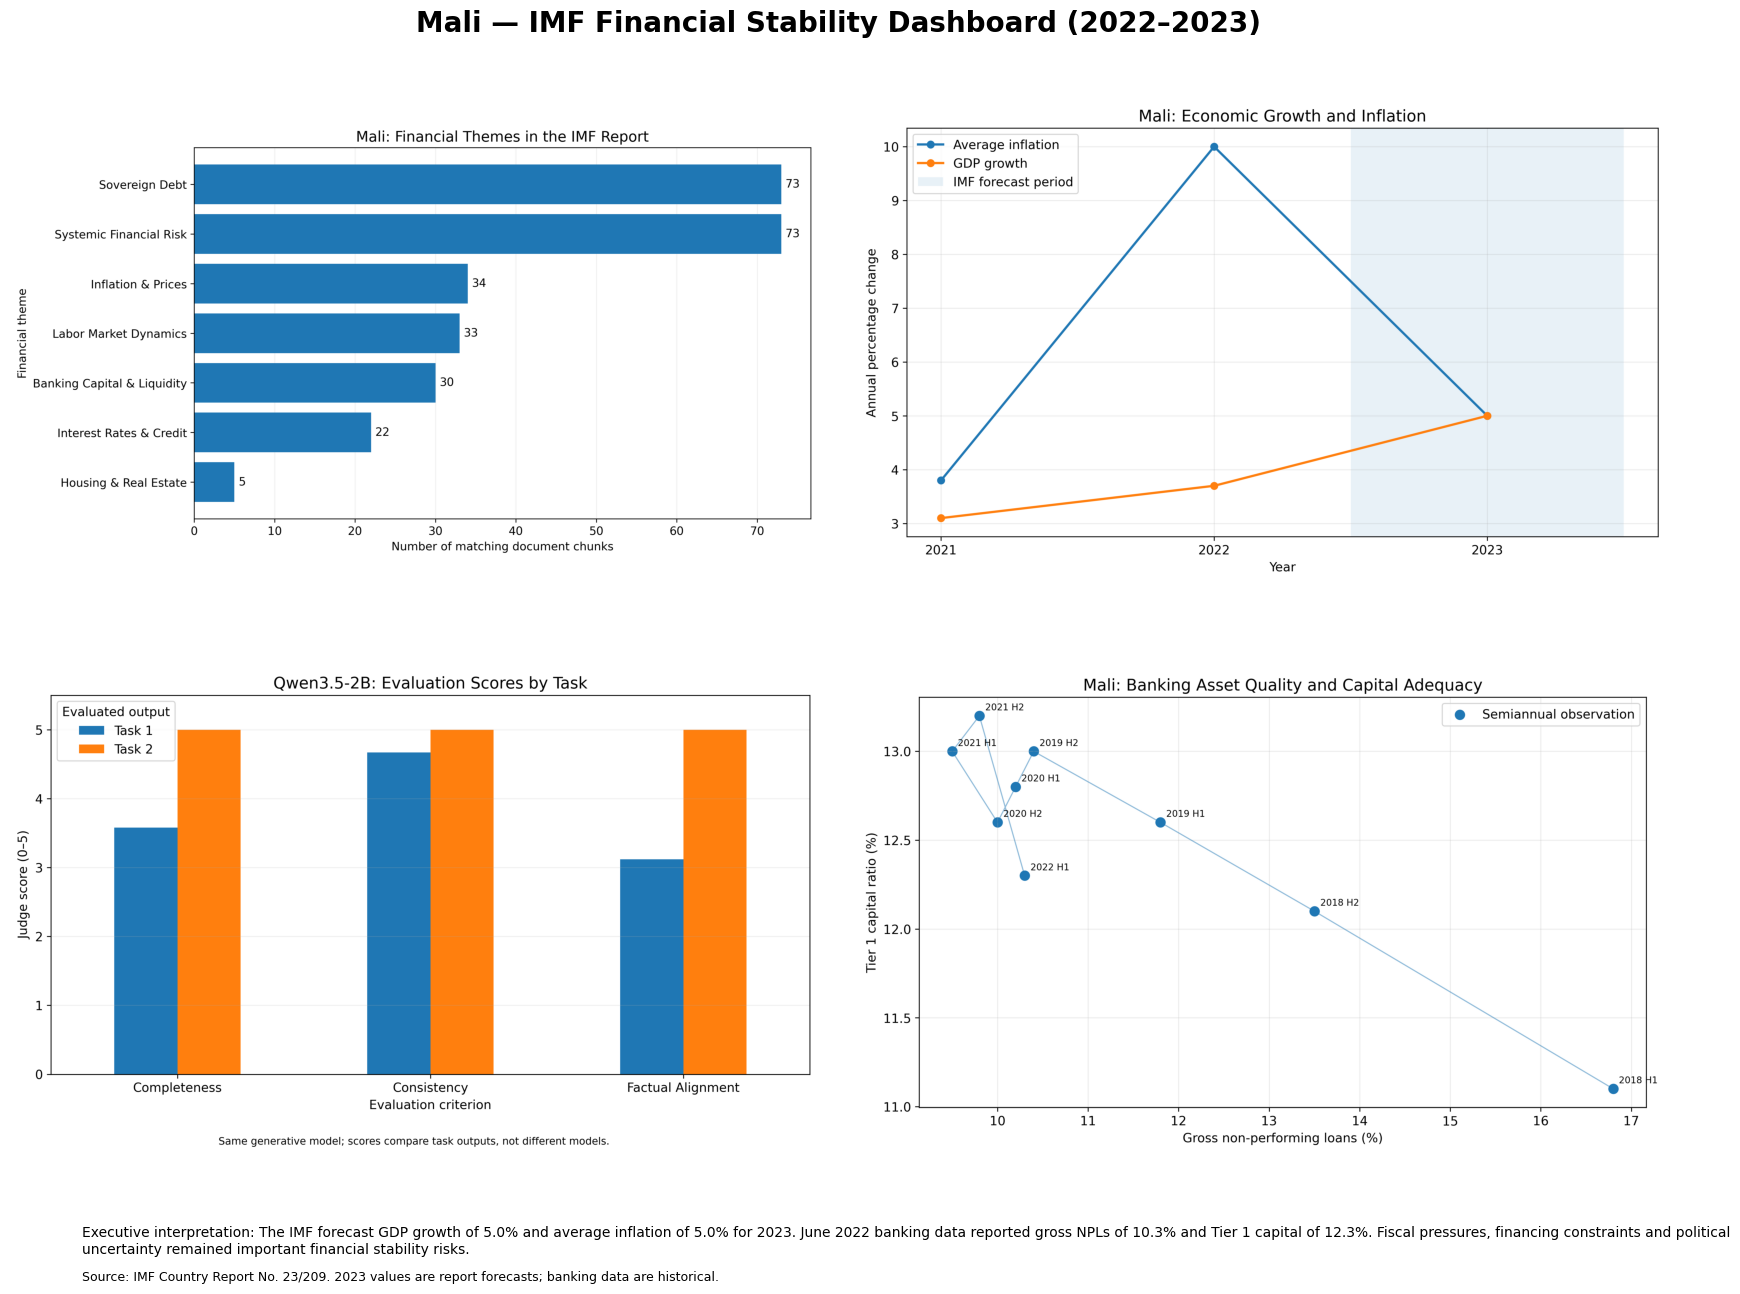


TASK 4 — OUTPUTS VERIFIED
Independent charts: 4
Resolution: 300 DPI
Dashboard: /content/mali_imf/figures/mali_financial_dashboard.png
Validation: All checks passed


In [20]:

# CELL 13 — DASHBOARD AND OUTPUT VALIDATION

import json
import matplotlib.pyplot as plt
from PIL import Image

names = [
    "figure1_theme_distribution.png",
    "figure2_macroeconomic_trends.png",
    "figure3_evaluation_scores.png",
    "figure4_banking_risk.png"
]

# Combine the four saved charts into one academic dashboard.
fig, axes = plt.subplots(2, 2, figsize=(18, 13))

for ax, name in zip(axes.flat, names):
    image = Image.open(FIGURES / name)
    ax.imshow(image)
    ax.axis("off")

fig.suptitle(
    "Mali — IMF Financial Stability Dashboard (2022–2023)",
    fontsize=20,
    fontweight="bold",
    y=0.99
)

# Use the verified figures from Task 2.
gdp_2023 = indicators["gdp_growth_forecast_pct"]
inflation_2023 = indicators["headline_inflation_rate_pct"]
npl = indicators["non_performing_loan_ratio"]
capital = indicators["tier_1_capital_ratio"]

interpretation = (
    f"Executive interpretation: The IMF forecast GDP growth of "
    f"{gdp_2023:.1f}% and average inflation of {inflation_2023:.1f}% "
    f"for 2023. June 2022 banking data reported gross NPLs of "
    f"{npl:.1f}% and Tier 1 capital of {capital:.1f}%. "
    "Fiscal pressures, financing constraints and political "
    "uncertainty remained important financial stability risks."
)

fig.text(
    0.08, 0.035,
    interpretation,
    fontsize=10,
    wrap=True
)

fig.text(
    0.08, 0.012,
    "Source: IMF Country Report No. 23/209. "
    "2023 values are report forecasts; banking data are historical.",
    fontsize=9
)

fig.subplots_adjust(
    left=0.04, right=0.96,
    top=0.93, bottom=0.10,
    hspace=0.12, wspace=0.05
)

dashboard = FIGURES / "mali_financial_dashboard.png"
fig.savefig(dashboard, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Confirm the four independent figures are present at 300 DPI.
validation = {}

for name in names:
    path = FIGURES / name

    with Image.open(path) as image:
        dpi = image.info.get("dpi", (0, 0))
        passed = (
            image.width >= 1500
            and image.height >= 1000
            and min(dpi) >= 298
        )

    validation[name] = passed

if not all(validation.values()):
    raise RuntimeError("One or more figures failed resolution checks.")

# Save the dashboard information and validation results.
manifest = {
    "country": "Mali",
    "report": "IMF Country Report No. 23/209",
    "generative_model": "Qwen3.5-2B",
    "figure_count": len(names),
    "resolution_dpi": 300,
    "figures": names,
    "dashboard": dashboard.name,
    "validation": validation,
    "executive_interpretation": interpretation
}

(ROOT / "task4_manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

print("\nTASK 4 — OUTPUTS VERIFIED")
print("Independent charts:", len(names))
print("Resolution: 300 DPI")
print("Dashboard:", dashboard)
print("Validation: All checks passed")
